# 03 RFM 用户分层

**RFM 模型**衡量用户价值三个维度：

| 维度 | 含义 | 本数据的度量 |
|---|---|---|
| R (Recency) | 最近一次购买距今多久 | 距 2014-12-18（数据期末）的天数，越小越好 |
| F (Frequency) | 购买频次 | 期内购买次数 |
| M (Monetary) | 消费金额 | **数据无金额字段**，本分析用 R、F 两维分层 |

**方法**：以购买记录为基础，R、F 各按中位数划"高/低"，交叉得到 4 类用户；
并对 R、F 做 1-5 分打分（分位数法），绘制分层散点图与占比图，输出运营建议。

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

df = pd.read_csv('data/userbehavior_1m.csv', dtype={'user_id': str})
df['time'] = pd.to_datetime(df['time'], format='%Y-%m-%d %H')
# 与 01 保持同一清洗口径：去 geohash 列 + 按行去重
df = df.drop(columns=['user_geohash']).drop_duplicates().reset_index(drop=True)
buys = df[df['behavior_type'] == 2].copy()   # 2 = 购买
print(f'购买记录 {len(buys):,} 条，购买用户 {buys["user_id"].nunique():,} 人')

购买记录 19,840 条，购买用户 3,604 人


## 一、计算 R / F

In [26]:
SNAPSHOT = buys['time'].max().normalize() + pd.Timedelta(days=1)  # 2014-12-19 normalize()：把时间归到当天零点，去掉时分秒
rf = buys.groupby('user_id').agg(
    last_buy=('time', 'max'),
    F=('time', 'count'),
)
rf['R'] = (SNAPSHOT - rf['last_buy'].dt.normalize()).dt.days
rf = rf[['R', 'F']]
print(f'观察期基准日：{SNAPSHOT.date()}')
rf.describe().round(2)

观察期基准日：2014-12-19


,R,F
count,3604.00,3604.00
mean,10.06,5.50
std,8.24,9.34
min,1.00,1.00
25%,3.00,1.00
50%,7.00,3.00
75%,15.00,6.00
max,31.00,230.00


## 二、R / F 打分与分层

- **R 得分**：R 越小（越近购买）得分越高 → 按 R 的 20/40/60/80 分位切 1~5 分；
- **F 得分**：购买次数越多得分越高 → 同样按分位切 1~5 分；
- **分层规则**：R 得分、F 得分各与中位数 3 比较，交叉出 4 类。

In [27]:
rf['r_score'] = pd.qcut(rf['R'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)   # R 越小分越高
rf['f_score'] = pd.qcut(rf['F'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

r_med, f_med = 3, 3
rf['segment'] = np.select(
    [(rf['r_score'] >= r_med) & (rf['f_score'] >= f_med),
    (rf['r_score'] >= r_med) & (rf['f_score'] < f_med),
    (rf['r_score'] < r_med) & (rf['f_score'] >= f_med)],
   ['重要价值客户', '重要发展客户', '重要保持客户'],
   default='重要挽留客户')

seg = rf['segment'].value_counts()
seg_pct = (seg / len(rf) * 100).round(1)
pd.DataFrame({'用户数': seg, '占比(%)': seg_pct})

,用户数,占比(%)
segment,,
重要价值客户,1672,46.4
重要挽留客户,862,23.9
重要发展客户,580,16.1
重要保持客户,490,13.6


In [37]:
# 各层 RF 特征
prof = rf.groupby('segment').agg(平均R=('R', 'mean'), 平均F=('F', 'mean'),
                                 用户数=('R', 'size')).round(2)
prof

,平均R,平均F,用户数
segment,,,
重要价值客户,4.29,9.58,1672
重要保持客户,16.41,4.32,490
重要发展客户,5.60,1.25,580
重要挽留客户,20.63,1.14,862


### 敏感性检验：固定阈值分层

主结果用中位数划分（相对分层，四层样本均衡）。这里换常用的固定阈值——
**7 天内买过 且 累计购买 ≥5 次 = 高价值**，检验分层结论对划分方式的敏感程度。



In [36]:
# 固定阈值：R ≤ 7 天（近期） 且 F ≥ 5 次（高频）算高价值
r_th, f_th = 7, 5

rf['segment_fixed'] = np.select(
    [(rf['R'] <= r_th) & (rf['F'] >= f_th),      # 近期 + 高频 = 价值
     (rf['R'] <= r_th) & (rf['F'] < f_th),       # 近期 + 低频 = 发展
     (rf['R'] > r_th) & (rf['F'] >= f_th)],      # 久未买 + 高频 = 保持
    ['重要价值客户', '重要发展客户', '重要保持客户'],
    default='重要挽留客户')                          # 久未买 + 低频 = 挽留

# 两种划分方式的占比对比
cmp = pd.concat([
    rf['segment'].value_counts(normalize=True).mul(100).round(1).rename('中位数法(%)'),
    rf['segment_fixed'].value_counts(normalize=True).mul(100).round(1).rename('固定阈值法(%)'),
], axis=1).sort_values('中位数法(%)', ascending=False)
cmp['变化(百分点)'] = (cmp['固定阈值法(%)'] - cmp['中位数法(%)']).round(1)
cmp



,中位数法(%),固定阈值法(%),变化(百分点)
重要价值客户,46.4,27.4,-19.0
重要挽留客户,23.9,41.8,17.9
重要发展客户,16.1,23.1,7.0
重要保持客户,13.6,7.7,-5.9


In [34]:
# 固定阈值下各层特征
rf.groupby('segment_fixed').agg(平均R=('R', 'mean'), 平均F=('F', 'mean'),
                                用户数=('R', 'size')).round(2)

,平均R,平均F,用户数
segment_fixed,,,
重要价值客户,3.20,13.40,988
重要保持客户,11.97,8.01,278
重要发展客户,4.12,2.17,831
重要挽留客户,17.47,1.71,1507


## 三、可视化

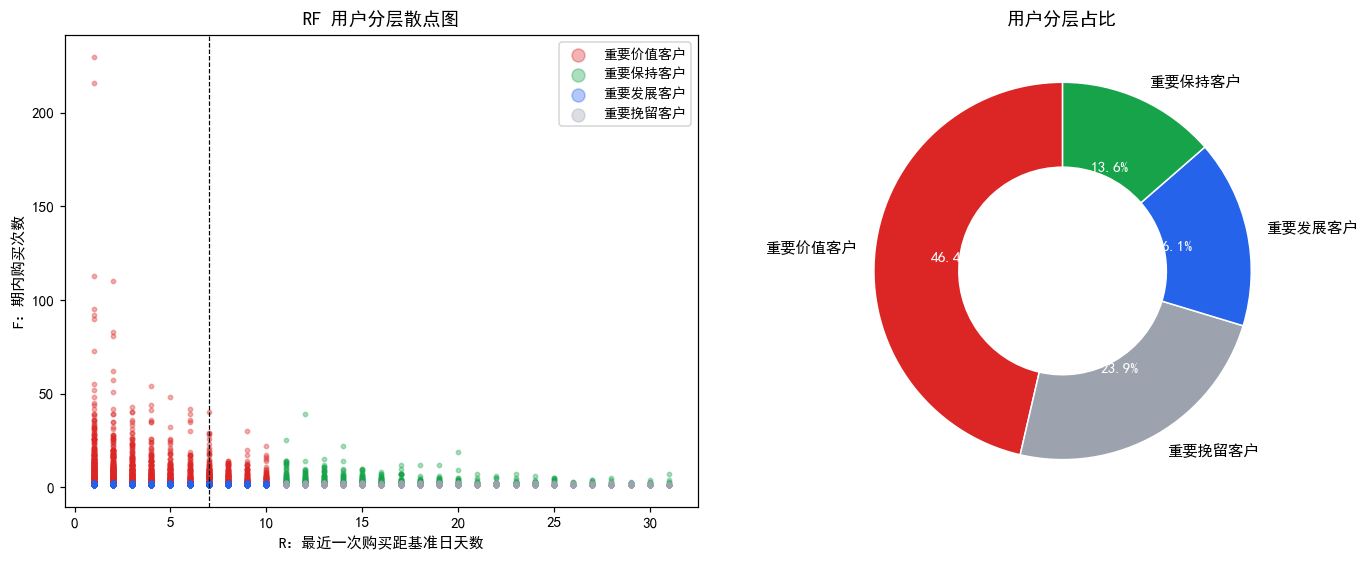

In [30]:
colors = {'重要价值客户': '#dc2626', '重要发展客户': '#2563eb',
          '重要保持客户': '#16a34a', '重要挽留客户': '#9ca3af'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
for name, g in rf.groupby('segment'):
    ax.scatter(g['R'], g['F'], s=8, alpha=.35, color=colors[name], label=name)
ax.axvline(rf['R'].median(), color='k', ls='--', lw=.8)
ax.set_xlabel('R：最近一次购买距基准日天数'); ax.set_ylabel('F：期内购买次数')
ax.set_title('RF 用户分层散点图'); ax.legend(markerscale=3, fontsize=9)
ax = axes[1]
wedges, texts, autotexts = ax.pie(seg.values, labels=seg.index, autopct='%1.1f%%',
       colors=[colors[k] for k in seg.index], startangle=90,
       wedgeprops=dict(width=.45, edgecolor='white'))
for t in autotexts: t.set_color('white'); t.set_fontweight('bold')
ax.set_title('用户分层占比')
fig.tight_layout()
fig.savefig('figures/03_RFM用户分层.png', dpi=150, bbox_inches='tight')
plt.show()

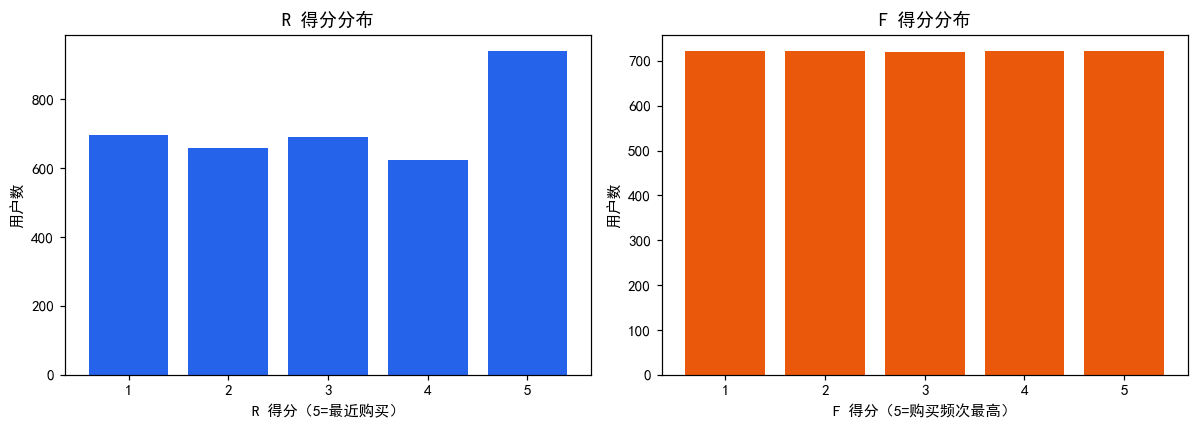

In [31]:
# F 得分与 R 得分的分布（打分合理性检查）
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(rf['r_score'].value_counts().sort_index().index,
            rf['r_score'].value_counts().sort_index().values, color='#2563eb')
axes[0].set_xlabel('R 得分（5=最近购买）'); axes[0].set_ylabel('用户数')
axes[0].set_title('R 得分分布')
axes[1].bar(rf['f_score'].value_counts().sort_index().index,
            rf['f_score'].value_counts().sort_index().values, color='#ea580c')
axes[1].set_xlabel('F 得分（5=购买频次最高）'); axes[1].set_ylabel('用户数')
axes[1].set_title('F 得分分布')
fig.tight_layout()
fig.savefig('figures/03_RF得分分布.png', dpi=150, bbox_inches='tight')
plt.show()

## 四、结论与运营建议

**分层结果（3,604 名购买用户，基准日 2014-12-19，R/F 按中位数 R≤7、F≤3 划高低）**

| 分层 | 用户数 | 占比 | 特征（R 均值 / F 均值） |
|---|---|---|---|
| 重要价值客户 | 1,672 | 46.4% | R 4.3 天、F 9.6 次，高频且近期活跃 |
| 重要挽留客户 | 862 | 23.9% | R 20.6 天、F 1.1 次，买过一次已濒临流失 |
| 重要发展客户 | 580 | 16.1% | R 5.6 天、F 1.3 次，近期活跃但只买过 1 次 |
| 重要保持客户 | 490 | 13.6% | R 16.4 天、F 4.3 次，历史高频但近期沉默 |

**业务建议**

1. **重要价值客户（46.4%）**：贡献主要复购，推送新品与会员权益维持黏性，避免过度打扰；
2. **重要挽留客户（23.9%）**：数量第二多、价值低、流失风险高，用大额券/爆款低价商品做低成本召回，不建议高成本触达；
3. **重要发展客户（16.1%）**：刚完成首购且近期活跃，是提升复购的最佳目标——首购后 7 天内推送关联商品与满减券；
4. **重要保持客户（13.6%）**：历史高频但近期沉默，曾是付费忠实用户，优先级最高的召回人群，用短信/Push 定向唤醒并结合大促节点。

> 注：数据无金额字段，M 维以购买频次近似衡量用户价值；

In [32]:
top_seg = seg.index[0]
print(f'最大分层：{top_seg}（{seg_pct.iloc[0]}%）')
print('高价值用户（重要价值客户+重要保持客户）占比：'
      f'{(seg.get("重要价值客户", 0) + seg.get("重要保持客户", 0)) / len(rf):.1%}')

最大分层：重要价值客户（46.4%）
高价值用户（重要价值客户+重要保持客户）占比：60.0%
